# IDX Exchange DS Internship - Week Six - Feature Engineering

In [38]:
import pandas as pd
import numpy as np
import geopandas as gpd
import matplotlib.pyplot as plt
from shapely.geometry import Point
from sklearn.preprocessing import TargetEncoder

In [39]:
# Read in the training and test sets created earlier

train_set = pd.read_csv("week_3_train_2.csv")
test_set = pd.read_csv("week_3_test_2.csv")

In [40]:
train_set.shape

(265350, 54)

## Bed/Bath Ratio

count    265350.000000
mean          1.309586
std           0.259424
min           0.200000
25%           1.200000
50%           1.333333
75%           1.500000
max           6.000000
Name: BedBathRatio, dtype: float64

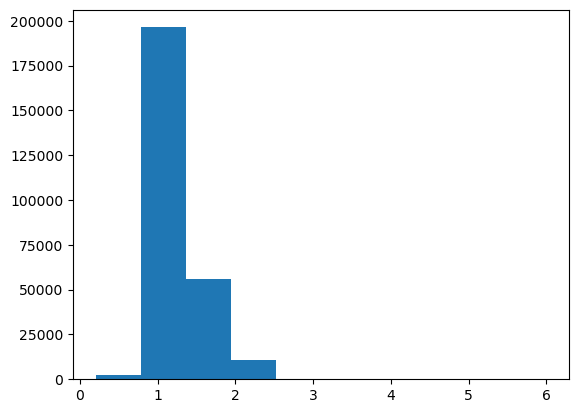

In [41]:
# Add one to both numerator and denominator to avoid dividing by zero

train_set["BedBathRatio"] =  (train_set["BedroomsTotal"] + 1) / (train_set["BathroomsTotalInteger"] + 1)
test_set["BedBathRatio"] =  (test_set["BedroomsTotal"] + 1) / (test_set["BathroomsTotalInteger"] + 1)

plt.hist(train_set["BedBathRatio"])
train_set["BedBathRatio"].describe()

## Age of Property

count    265350.000000
mean         49.091946
std          27.368242
min          -1.000000
25%          27.000000
50%          49.000000
75%          69.000000
max         249.000000
Name: PropertyAge, dtype: float64

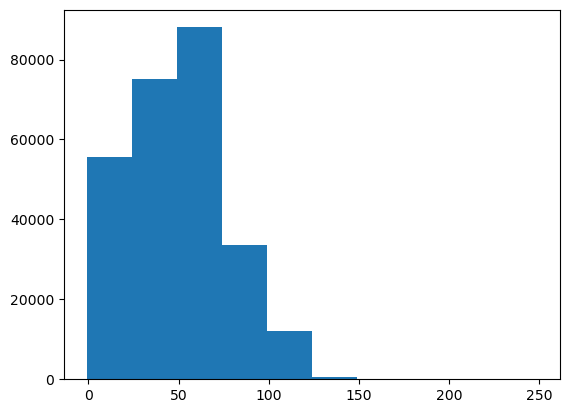

In [42]:
# Reminder: YearBuilt was imputed with the median YearBuilt of properties in each city

year_listed = pd.to_datetime(pd.to_datetime(train_set["PropertyMonth"]).dt.strftime("%Y"))
year_made = pd.to_datetime(train_set["YearBuilt"], format="%Y")
train_set["PropertyAge"] = year_listed.dt.year - year_made.dt.year

year_listed = pd.to_datetime(pd.to_datetime(test_set["PropertyMonth"]).dt.strftime("%Y"))
year_made = pd.to_datetime(test_set["YearBuilt"], format="%Y")
test_set["PropertyAge"] = year_listed.dt.year - year_made.dt.year

plt.hist(train_set["PropertyAge"])
train_set["PropertyAge"].describe()

## Precise School Districts

In [116]:
# HighSchoolDistrict has a high amount of Unknown values
# Use the California School District Areas dataset to fill these
# Link to site: https://data.ca.gov/@california-department-of-education/california-school-district-areas-2024-25

gdf_geojson = gpd.read_file("California_School_District_Areas_2024-25.geojson")

In [117]:
gdf_geojson.columns

Index(['OBJECTID', 'Year', 'FedID', 'CDCode', 'CDSCode', 'CountyName',
       'DistrictName', 'DistrictType', 'GradeLow', 'GradeHigh',
       'GradeLowCensus', 'GradeHighCensus', 'AssistStatus', 'CongressUS',
       'SenateCA', 'AssemblyCA', 'UpdateNotes', 'EnrollTotal', 'EnrollCharter',
       'EnrollNonCharter', 'AAcount', 'AApct', 'AIcount', 'AIpct', 'AScount',
       'ASpct', 'FIcount', 'FIpct', 'HIcount', 'HIpct', 'PIcount', 'PIpct',
       'WHcount', 'WHpct', 'MRcount', 'MRpct', 'NRcount', 'NRpct', 'ELcount',
       'ELpct', 'FOScount', 'FOSpct', 'HOMcount', 'HOMpct', 'MIGcount',
       'MIGpct', 'SWDcount', 'SWDpct', 'SEDcount', 'SEDpct', 'DistrctAreaSqMi',
       'Shape__Area', 'Shape__Length', 'geometry'],
      dtype='object')

In [118]:
# A lot of these columns are just metadata. Keep only the relevant columns
# The kept columns relate to the name/type/county of the district, as well as enrollment counts and demographic information

cols_to_keep = ["CountyName", "DistrictName", "DistrictType",
                "EnrollTotal", "EnrollCharter", "EnrollNonCharter",
                "AApct", "AAcount", "AIpct", "AIcount", "ASpct", "AScount", "FIpct", "FIcount",
                "HIpct", "HIcount", "PIpct", "PIcount", "WHpct", "WHcount", "MRpct", "MRcount", 
                "NRpct", "NRcount", "ELpct", "ELcount", "FOSpct", "FOScount", "HOMpct", "HOMcount", 
                "MIGpct", "MIGcount", "SWDpct", "SWDcount", "SEDpct", "SEDcount", 
                "geometry"]

gdf_geojson = gdf_geojson[cols_to_keep]

In [119]:
### Merging the dataset naively creates duplicate rows where one property is matched to both its elementary
### and high school district, creating two rows for one property. To fix this, we must sequentially join the
### data together based on district type (high, elementary, unified).

### High School Distict Joining

# Convert train_set to a GeoDataFrame using points_from_xy
geo_high = gdf_geojson[gdf_geojson["DistrictType"] == "High"]

geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")

# Ensure both GeoDataFrames have the same Coordinate Reference System (CRS)
geo_high = geo_high.to_crs(gdf_points.crs)

# Join the dataframes
geo_high_train = gpd.sjoin(gdf_points, geo_high, how="left", predicate="within")

# Do the same for the test set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_high = geo_high.to_crs(gdf_points.crs)
geo_high_test = gpd.sjoin(gdf_points, geo_high, how="left", predicate="within")

In [120]:
### Elementary School District Joining

# Convert train_set to a GeoDataFrame using points_from_xy
geo_elem = gdf_geojson[gdf_geojson["DistrictType"] == "Elementary"]

geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")

# Ensure both GeoDataFrames have the same Coordinate Reference System (CRS)
geo_elem = geo_elem.to_crs(gdf_points.crs)

# Join the dataframes
geo_elem_train = gpd.sjoin(gdf_points, geo_elem, how="left", predicate="within")

# Do the same for the test set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_elem = geo_elem.to_crs(gdf_points.crs)
geo_elem_test = gpd.sjoin(gdf_points, geo_elem, how="left", predicate="within")

In [121]:
### Unified School District Joining

# Convert train_set to a GeoDataFrame using points_from_xy
geo_unif = gdf_geojson[gdf_geojson["DistrictType"] == "Unified"]

geometry = gpd.points_from_xy(train_set["Longitude"], train_set["Latitude"])
gdf_points = gpd.GeoDataFrame(train_set, geometry=geometry, crs="EPSG:4326")

# Ensure both GeoDataFrames have the same Coordinate Reference System (CRS)
geo_unif = geo_unif.to_crs(gdf_points.crs)

# Join the dataframes
geo_unif_train = gpd.sjoin(gdf_points, geo_unif, how="left", predicate="within")

# Do the same for the test set
geometry = gpd.points_from_xy(test_set["Longitude"], test_set["Latitude"])
gdf_points = gpd.GeoDataFrame(test_set, geometry=geometry, crs="EPSG:4326")
geo_unif = geo_unif.to_crs(gdf_points.crs)
geo_unif_test = gpd.sjoin(gdf_points, geo_unif, how="left", predicate="within")

In [122]:
geo_elem_train = geo_elem_train[cols_to_keep]
geo_unif_train = geo_unif_train[cols_to_keep]
geo_unif_train = geo_unif_train.add_suffix('_unif')
geo_train = geo_high_train.join(geo_elem_train, how="inner", lsuffix='_high', rsuffix='_elem').join(geo_unif_train, how="inner")

geo_elem_test = geo_elem_test[cols_to_keep]
geo_unif_test = geo_unif_test[cols_to_keep]
geo_unif_test = geo_unif_test.add_suffix('_unif')
geo_test = geo_high_test.join(geo_elem_test, how="inner", lsuffix='_high', rsuffix='_elem').join(geo_unif_test, how="inner")

In [123]:
geo_train[["HighSchoolDistrict", "DistrictName_elem", "DistrictType_elem", "DistrictName_high", "DistrictType_high", "DistrictName_unif", "DistrictType_unif"]]

,HighSchoolDistrict,DistrictName_elem,DistrictType_elem,DistrictName_high,DistrictType_high,DistrictName_unif,DistrictType_unif
0,Unknown,National Elementary,Elementary,Sweetwater Union High,High,NaN,NaN
1,Unknown,National Elementary,Elementary,Sweetwater Union High,High,NaN,NaN
2,San Luis Coastal Unified,NaN,NaN,NaN,NaN,San Luis Coastal Unified,Unified
3,Unknown,NaN,NaN,NaN,NaN,Fort Bragg Unified,Unified
4,Other,Evergreen Elementary,Elementary,East Side Union High,High,NaN,NaN
...,...,...,...,...,...,...,...
265345,Los Angeles Unified,NaN,NaN,NaN,NaN,Los Angeles Unified,Unified
265346,Los Angeles Unified,NaN,NaN,NaN,NaN,Los Angeles Unified,Unified
265347,Victor Valley Unified,Adelanto Elementary,Elementary,Victor Valley Union High,High,NaN,NaN
265348,Rim of the World,NaN,NaN,NaN,NaN,Rim of the World Unified,Unified


In [124]:
# Check if there are any rows in the MLS data that could not be matched to any school district
# It seems that most of these rows show up as "Unknown" or "Other" 

condition_train = (geo_train["DistrictName_high"].isna() == True) & (geo_train["DistrictName_elem"].isna() == True) & (geo_train["DistrictName_unif"].isna() == True)
condition_test = (geo_test["DistrictName_high"].isna() == True) & (geo_test["DistrictName_elem"].isna() == True) & (geo_test["DistrictName_unif"].isna() == True)

geo_train[condition_train]["HighSchoolDistrict"].value_counts()

# Since there are only 36 of these rows, this is a low enough number to just drop
geo_train = geo_train.drop(geo_train[condition_train].index).reset_index(drop=True)
geo_test = geo_test.drop(geo_test[condition_test].index).reset_index(drop=True)

In [125]:
# This information is encoded in the column title of DistrictName

geo_train = geo_train.drop(columns = ["DistrictType_elem", "DistrictType_high", "DistrictType_unif"])
geo_test = geo_test.drop(columns = ["DistrictType_elem", "DistrictType_high", "DistrictType_unif"])

In [126]:
geo_train[["HighSchoolDistrict", "DistrictName_elem", "DistrictName_high", "DistrictName_unif"]]

,HighSchoolDistrict,DistrictName_elem,DistrictName_high,DistrictName_unif
0,Unknown,National Elementary,Sweetwater Union High,NaN
1,Unknown,National Elementary,Sweetwater Union High,NaN
2,San Luis Coastal Unified,NaN,NaN,San Luis Coastal Unified
3,Unknown,NaN,NaN,Fort Bragg Unified
4,Other,Evergreen Elementary,East Side Union High,NaN
...,...,...,...,...
265309,Los Angeles Unified,NaN,NaN,Los Angeles Unified
265310,Los Angeles Unified,NaN,NaN,Los Angeles Unified
265311,Victor Valley Unified,Adelanto Elementary,Victor Valley Union High,NaN
265312,Rim of the World,NaN,NaN,Rim of the World Unified


In [127]:
# Fill Unknown HighSchoolDistrict with DistrictName

geo_train["HighSchoolDistrict"] = np.where(geo_train["HighSchoolDistrict"] == "Unknown",
                                           geo_train["DistrictName_high"], geo_train["HighSchoolDistrict"])
geo_train["HighSchoolDistrict"] = np.where(geo_train["HighSchoolDistrict"] == "Other",
                                            geo_train["DistrictName_high"], geo_train["HighSchoolDistrict"])

geo_test["HighSchoolDistrict"] = np.where(geo_test["HighSchoolDistrict"] == "Unknown",
                                            geo_test["DistrictName_high"], geo_test["HighSchoolDistrict"])
geo_test["HighSchoolDistrict"] = np.where(geo_test["HighSchoolDistrict"] == "Other",
                                            geo_test["DistrictName_high"], geo_test["HighSchoolDistrict"])

In [128]:
# Now HighSchoolDistrict serves as DistrictName_high, so drop DistrictName_high

geo_train = geo_train.drop(columns = ["DistrictName_high"])
geo_test = geo_test.drop(columns = ["DistrictName_high"])

In [129]:
# Clean up remaning rows

geo_train = geo_train.rename(columns={"HighSchoolDistrict": "DistrictName_high"})
geo_test = geo_test.rename(columns={"HighSchoolDistrict": "DistrictName_high"})

geo_train = geo_train.drop(columns = ["geometry_high", "index_right", "CountyName_high", "CountyName_elem", "geometry_elem",
                                      "CountyName_unif", "geometry_unif"])
geo_test = geo_test.drop(columns = ["geometry_high", "index_right", "CountyName_high", "CountyName_elem", "geometry_elem",
                                      "CountyName_unif", "geometry_unif"])

In [130]:
# Fill categorical null values with "N/A"
cat = ["DistrictName_elem", "DistrictName_unif", "DistrictName_high"]
 
geo_train[cat] = geo_train[cat].fillna("N/A")
geo_test[cat] = geo_test[cat].fillna("N/A")

# Fill numerical null values with 0
num =  ['EnrollTotal_high', 'EnrollCharter_high', 'EnrollNonCharter_high', 'AApct_high', 'AAcount_high', 'AIpct_high',
        'AIcount_high', 'ASpct_high', 'AScount_high', 'FIpct_high', 'FIcount_high', 'HIpct_high', 'HIcount_high', 'PIpct_high',
        'PIcount_high', 'WHpct_high', 'WHcount_high', 'MRpct_high', 'MRcount_high', 'NRpct_high', 'NRcount_high', 'ELpct_high',
        'ELcount_high', 'FOSpct_high', 'FOScount_high','HOMpct_high','HOMcount_high','MIGpct_high','MIGcount_high','SWDpct_high',
        'SWDcount_high','SEDpct_high','SEDcount_high', 'EnrollTotal_elem','EnrollCharter_elem','EnrollNonCharter_elem','AApct_elem',
        'AAcount_elem','AIpct_elem','AIcount_elem','ASpct_elem','AScount_elem','FIpct_elem','FIcount_elem','HIpct_elem','HIcount_elem',
        'PIpct_elem','PIcount_elem','WHpct_elem','WHcount_elem','MRpct_elem','MRcount_elem','NRpct_elem','NRcount_elem','ELpct_elem',
        'ELcount_elem','FOSpct_elem','FOScount_elem','HOMpct_elem','HOMcount_elem','MIGpct_elem','MIGcount_elem','SWDpct_elem',
        'SWDcount_elem','SEDpct_elem','SEDcount_elem','EnrollTotal_unif','EnrollCharter_unif','EnrollNonCharter_unif','AApct_unif',
        'AAcount_unif','AIpct_unif','AIcount_unif','ASpct_unif','AScount_unif','FIpct_unif','FIcount_unif','HIpct_unif','HIcount_unif',
        'PIpct_unif','PIcount_unif','WHpct_unif','WHcount_unif','MRpct_unif','MRcount_unif','NRpct_unif','NRcount_unif','ELpct_unif',
        'ELcount_unif','FOSpct_unif','FOScount_unif','HOMpct_unif','HOMcount_unif','MIGpct_unif','MIGcount_unif','SWDpct_unif',
        'SWDcount_unif','SEDpct_unif','SEDcount_unif']

geo_train[num] = geo_train[num].fillna(0)
geo_test[num] = geo_test[num].fillna(0)

## Target Encode the Categorical Variables

In [133]:
# Perform target encoding on: DistrictName_elem, DistrictName_unif, DistrictName_high

to_encode_train = geo_train[cat]
to_encode_test = geo_test[cat]

encoder = TargetEncoder(smooth="auto", cv=5, random_state=42)

train_encoded = encoder.fit_transform(to_encode_train, geo_train["ClosePriceLog"])
test_encoded = encoder.transform(to_encode_test)

train_encoded_df = pd.DataFrame(train_encoded, columns=to_encode_train.columns)
test_encoded_df = pd.DataFrame(test_encoded, columns=to_encode_train.columns)

geo_train = geo_train.join(train_encoded_df, rsuffix='_enc')
geo_test = geo_test.join(test_encoded_df, rsuffix='_enc')

In [134]:
geo_train.to_csv("feat_eng_train.csv", index=False)
geo_test.to_csv("feat_eng_test.csv", index=False)